# First Machine Learning Classifier

## 1. Project Overview

This project focuses on building a supervised machine learning classification model using Scikit-Learn. A Decision Tree Classifier will be trained using the Titanic dataset to predict passenger survival.

## 2. Prediction Definition

The objective is to predict whether a passenger survived the Titanic disaster based on their passenger class, gender, age, and ticket fare.

**Target Variable:** survived

**Features:** pclass, sex, age, fare

## 3. Importing Required Libraries

The required Python libraries are imported to load the Titanic dataset, prepare the data, build the Decision Tree model, and evaluate its performance.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

print("All libraries imported successfully!")

All libraries imported successfully!


## 4. Load the Titanic Dataset

### 4.1 Dataset Description
The Titanic dataset is used for this classification project. It contains passenger information, including survival status, passenger class, gender, age, and ticket fare. The dataset will be used to train and evaluate the machine learning model.

### 4.2 Load the Dataset

In [2]:
df = sns.load_dataset("titanic")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


### 4.3 Dataset Information

The dataset structure is examined to understand its columns, data types, and missing values. This helps identify the information required for preparing the classification model.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


### 4.4 Dataset Observations

The Titanic dataset contains 891 passenger records and 15 columns. The dataset includes passenger details such as survival status, passenger class, gender, age, and ticket fare.

During the initial inspection, missing values were identified in the age, embarked, and deck columns. The age column contains 177 missing values, while embarked contains 2 missing values and deck contains 688 missing values.

For this project, only five required columns are selected: survived, pclass, sex, age, and fare. These columns are used to prepare the dataset for building the Decision Tree Classification model.

## 5. Data Preparation

### 5.1 Select Required Columns
Data preparation is performed to select the required features and target variable for the classification model. Missing values are handled, and categorical data is converted into numerical format so that the machine learning algorithm can process it.

### 5.2 Select Required Features

In [4]:
df = df[["survived", "pclass", "sex", "age", "fare"]]

print("Required columns selected successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Required columns selected successfully!
Dataset Shape: (891, 5)


,survived,pclass,sex,age,fare
0,0,3,male,22.0,7.2500
1,1,1,female,38.0,71.2833
2,1,3,female,26.0,7.9250
3,1,1,female,35.0,53.1000
4,0,3,male,35.0,8.0500


### 5.3 Handling Missing Values

Missing values in the selected columns are identified and removed to prepare a clean dataset. This ensures that the machine learning model receives complete records during training and evaluation.

In [5]:
print("Missing Values Before Cleaning:")
print(df.isnull().sum())

df = df.dropna()

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nCleaned Dataset Shape:", df.shape)

Missing Values Before Cleaning:
survived      0
pclass        0
sex           0
age         177
fare          0
dtype: int64

Missing Values After Cleaning:
survived    0
pclass      0
sex         0
age         0
fare        0
dtype: int64

Cleaned Dataset Shape: (714, 5)


### 5.4 Gender Encoding

The gender column contains categorical values. It is converted into numerical values, where female is represented as 1 and male as 0. This makes the data suitable for the Decision Tree Classifier.

In [6]:
df["sex"] = (df["sex"] == "female").astype(int)

print("Gender converted into numerical values!")

display(df.head())

Gender converted into numerical values!


,survived,pclass,sex,age,fare
0,0,3,0,22.0,7.2500
1,1,1,1,38.0,71.2833
2,1,3,1,26.0,7.9250
3,1,1,1,35.0,53.1000
4,0,3,0,35.0,8.0500


### 5.5 Prepared Dataset Verification

The prepared dataset is checked to confirm that all required columns are available, missing values have been removed, and gender has been converted into numerical format.

In [7]:
print("Final Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nFinal Dataset Shape:", df.shape)

display(df.head())

Final Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 714 entries, 0 to 890
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  714 non-null    int64  
 1   pclass    714 non-null    int64  
 2   sex       714 non-null    int64  
 3   age       714 non-null    float64
 4   fare      714 non-null    float64
dtypes: float64(2), int64(3)
memory usage: 33.5 KB
None

Missing Values:
survived    0
pclass      0
sex         0
age         0
fare        0
dtype: int64

Final Dataset Shape: (714, 5)


,survived,pclass,sex,age,fare
0,0,3,0,22.0,7.2500
1,1,1,1,38.0,71.2833
2,1,3,1,26.0,7.9250
3,1,1,1,35.0,53.1000
4,0,3,0,35.0,8.0500


## 6. Train/Test Split

###6.1 Define Features and Target

The prepared dataset is divided into features and a target variable. The target variable is survival status, while passenger class, gender, age, and fare are used as input features. The dataset is then divided into training and testing sets to evaluate the model on unseen data.

In [8]:
X = df.drop(columns="survived")
y = df["survived"]

print("Features and target separated successfully!")

print("\nFeature Columns:")
print(X.columns.tolist())

print("\nTarget Column:")
print(y.name)

Features and target separated successfully!

Feature Columns:
['pclass', 'sex', 'age', 'fare']

Target Column:
survived


### 6.2 Performing Train/Test Split

The dataset is divided into 80% training data and 20% testing data using Scikit-Learn. The random state ensures reproducible results, while stratification maintains a similar survival-class distribution in both sets.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train/Test split completed successfully!")

print("\nTraining Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Train/Test split completed successfully!

Training Features Shape: (571, 4)
Testing Features Shape: (143, 4)

Training Target Shape: (571,)
Testing Target Shape: (143,)


### 6.3 Verifying Survival Distribution

The survival distribution in the training and testing datasets is checked to confirm that stratification maintains a similar proportion of survived and non-survived passengers in both sets.

In [10]:
print("Training Set Survival Distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting Set Survival Distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training Set Survival Distribution:
survived
0    0.594
1    0.406
Name: proportion, dtype: float64

Testing Set Survival Distribution:
survived
0    0.594
1    0.406
Name: proportion, dtype: float64


## 7. Baseline Accuracy

### 7.1 Calculate Baseline Accuracy
Baseline accuracy is calculated by predicting the most common survival outcome for every passenger in the testing dataset. This provides a simple reference point to compare the performance of the Decision Tree classification model.

In [11]:
baseline_accuracy = max(y_test.mean(), 1 - y_test.mean())

print("Baseline Accuracy:", round(baseline_accuracy, 3))
print("Baseline Accuracy Percentage:", round(baseline_accuracy * 100, 2), "%")

Baseline Accuracy: 0.594
Baseline Accuracy Percentage: 59.44 %


### 7.2 Baseline Observation

The baseline model predicts the majority survival class for every passenger. It achieves approximately 59.4% accuracy and serves as the minimum performance reference for evaluating the Decision Tree model.

## 8. Decision Tree Model Training

### 8.1 Model Training

A Decision Tree Classifier is trained using the prepared training dataset. The model learns patterns from passenger class, gender, age, and fare to predict survival status. A maximum tree depth of 4 is used to control model complexity.

In [12]:
model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

model.fit(X_train, y_train)

print("Decision Tree Model trained successfully!")

Decision Tree Model trained successfully!


### 8.2 Generating Model Predictions

The trained Decision Tree model is used to predict passenger survival on the testing dataset. These predictions are compared with the actual survival outcomes to evaluate model performance on unseen data.

In [13]:
y_pred = model.predict(X_test)

print("Predictions generated successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.head(10).tolist())

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])

Predictions generated successfully!

First 10 Actual Values:
[1, 1, 0, 0, 1, 0, 0, 0, 0, 1]

First 10 Predicted Values:
[1 0 0 0 0 0 0 0 0 1]


## 9. Model Evaluation

### 9.1 Calculate Model Accuracy

The trained Decision Tree model is evaluated using the testing dataset. Accuracy and a confusion matrix are calculated to measure how correctly the model predicts passenger survival.

In [14]:
model_accuracy = accuracy_score(y_test, y_pred)

print("Baseline Accuracy:", round(baseline_accuracy * 100, 2), "%")
print("Decision Tree Model Accuracy:", round(model_accuracy * 100, 2), "%")

Baseline Accuracy: 59.44 %
Decision Tree Model Accuracy: 79.72 %


### 9.2 Confusion Matrix

A confusion matrix is used to compare actual survival outcomes with predicted outcomes. It shows the number of correct and incorrect predictions made by the classification model.

In [15]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[72 13]
 [16 42]]


### 9.3 Confusion Matrix Visualization

A heatmap is created to visualize the confusion matrix. It helps identify correct and incorrect predictions for both survival classes.

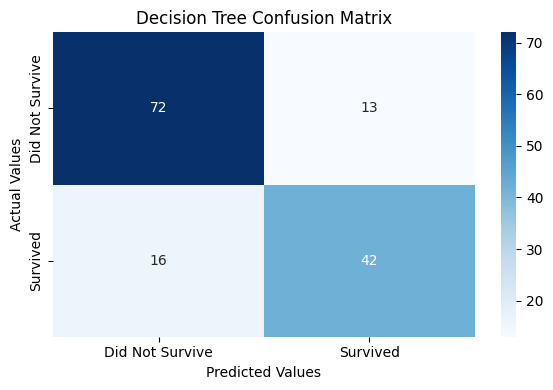

In [16]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Did Not Survive", "Survived"],
    yticklabels=["Did Not Survive", "Survived"]
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.tight_layout()
plt.show()

### 9.4 Confusion Matrix Interpretation

The confusion matrix shows 72 true negatives and 42 true positives, representing correct predictions. It also shows 13 false positives and 16 false negatives, representing incorrect predictions. The model successfully identifies both survived and non-survived passengers.

### 9.5 Baseline and Model Comparison

The Decision Tree model achieved 79.72% accuracy, outperforming the baseline accuracy of 59.44%. This indicates that the trained model performs better than simply predicting the majority survival class.

## 10. Tree Depth and Overfitting

### 10.1 Train Models with Different Tree Depths

Different Decision Tree depths are tested to understand how model complexity affects training and testing accuracy. This helps identify overfitting and evaluate the model's ability to perform on unseen data.

In [17]:
train_accuracies = []
test_accuracies = []
depth_values = range(1, 13)

for depth in depth_values:

    tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    tree.fit(X_train, y_train)

    train_pred = tree.predict(X_train)
    test_pred = tree.predict(X_test)

    train_accuracies.append(accuracy_score(y_train, train_pred))
    test_accuracies.append(accuracy_score(y_test, test_pred))

print("Tree depth testing completed!")

depth_results = pd.DataFrame({
    "Tree Depth": list(depth_values),
    "Training Accuracy": train_accuracies,
    "Testing Accuracy": test_accuracies
})

display(depth_results.round(3))

Tree depth testing completed!


,Tree Depth,Training Accuracy,Testing Accuracy
0,1,0.779,0.783
1,2,0.795,0.776
2,3,0.818,0.811
3,4,0.848,0.797
4,5,0.865,0.762
5,6,0.883,0.783
6,7,0.916,0.783
7,8,0.925,0.790
8,9,0.947,0.769
9,10,0.956,0.762


### 10.2 Visualizing Accuracy at Different Tree Depths

A line graph is used to compare training and testing accuracy across different tree depths. This helps identify the effect of model complexity and understand overfitting.

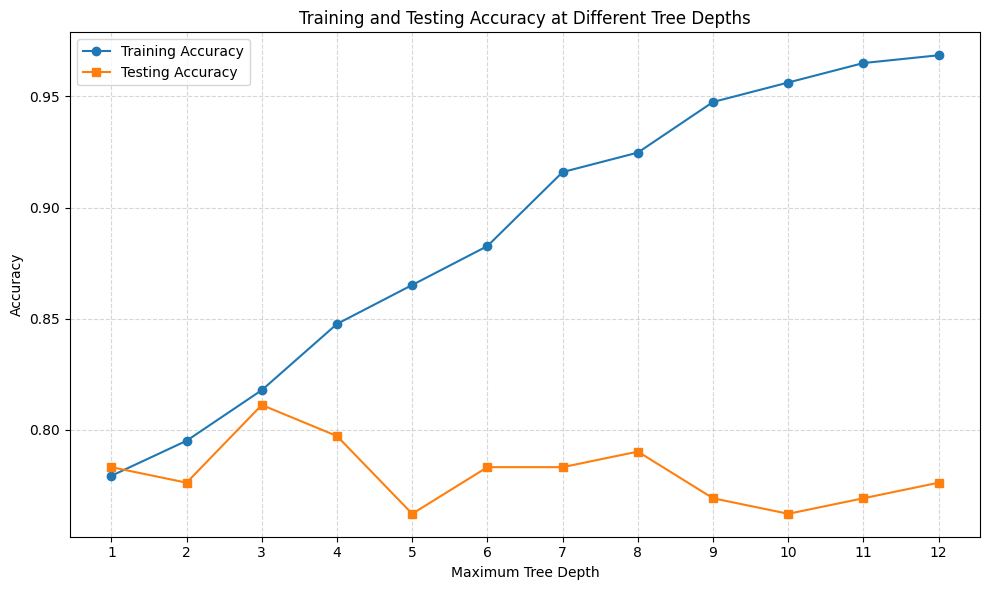

In [18]:
plt.figure(figsize=(10, 6))

plt.plot(
    depth_results["Tree Depth"],
    depth_results["Training Accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depth_results["Tree Depth"],
    depth_results["Testing Accuracy"],
    marker="s",
    label="Testing Accuracy"
)

plt.title("Training and Testing Accuracy at Different Tree Depths")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.xticks(range(1, 13))
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

### 10.3 Overfitting Observation

Training accuracy increases from 77.9% at depth 1 to 96.8% at depth 12. However, testing accuracy does not increase consistently. The highest testing accuracy is 81.1% at depth 3. Deeper trees can memorize training data and perform less effectively on unseen data. This indicates overfitting at higher tree depths.

## 11. Feature Importance

Feature importance helps identify which input variables contribute most to the model's predictions. We will compare the importance of passenger class, sex, age, and fare.

### 11.1 Calculating Feature Importance

The Decision Tree model provides feature importance scores. Higher scores indicate that a feature contributed more to the model's decisions.

In [19]:
feature_importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Feature Importance Scores:")
display(feature_importance.round(3))

Feature Importance Scores:


,0
sex,0.545
pclass,0.235
age,0.138
fare,0.082


### 11.2 Visualizing Feature Importance

A bar chart is used to compare the importance scores of all four features. This makes it easier to identify the most influential feature.

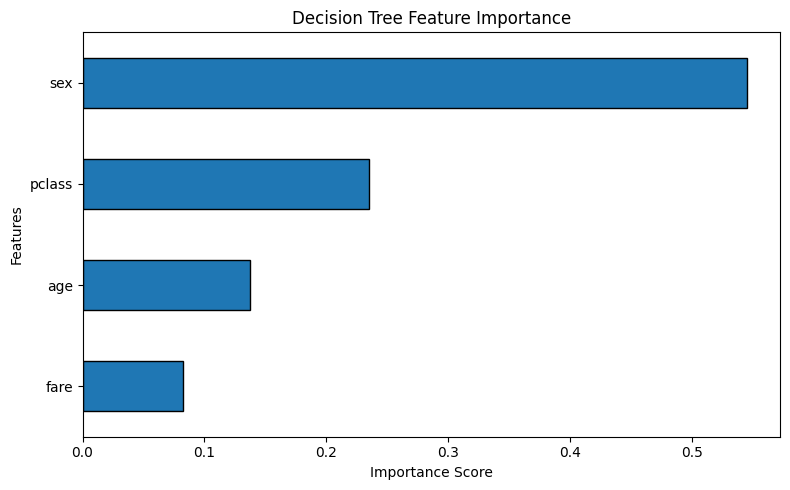

In [21]:
plt.figure(figsize=(8, 5))

feature_importance.sort_values().plot(
    kind="barh",
    edgecolor="black"
)

plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

### 11.3 Feature Importance Observation

The results show that sex is the most important feature, with an importance score of 0.545. Passenger class ranks second with 0.235, followed by age with 0.138. Fare has the lowest importance score of 0.082. Therefore, sex contributes the most to the Decision Tree model's predictions.

### 11.4 Key Findings

- Most important feature: Sex (0.545).
- Second important feature: Pclass (0.235).
- Least important feature: Fare (0.082).
- All four features contributed to predictions.

## 12. Final Project Summary

### 12.1 Overall Results

This project used a Decision Tree Classifier to predict Titanic passenger survival. Four features were used: passenger class, sex, age, and fare. The model achieved 79.72% testing accuracy, compared with the baseline accuracy of 59.44%. The confusion matrix showed 72 true negatives, 42 true positives, 13 false positives, and 16 false negatives. Sex was the most important feature, with an importance score of 0.545.

### 12.2 Project Limitation

The dataset originally contained 891 passenger records. However, 177 records with missing age values were removed during data cleaning. Therefore, the model was trained using only 714 complete records, which may limit its ability to represent all passengers.

### 12.3 What I Learned

- Prepared and cleaned a dataset.
- Converted categorical data into numerical values.
- Split data into training and testing sets.
- Calculated baseline accuracy.
- Trained a Decision Tree Classifier.
- Evaluated accuracy and confusion matrix.
- Understood feature importance and overfitting.

## 13. Conclusion

This project successfully demonstrated how Machine Learning can be used to predict Titanic passenger survival. The Decision Tree Classifier achieved 79.72% testing accuracy, outperforming the baseline accuracy of 59.44%. The project also demonstrated data preprocessing, model evaluation, feature importance, and overfitting analysis. Through this project, the basic Machine Learning classification workflow was successfully implemented.